# Cleaning the GES SHS list PDF

Source: `data/raw/ges_shs_list.pdf` ("Complete List of Senior High Schools in Ghana - Categories & Details", re-presented by myshsrank.com from the GES public SHS list).


In [2]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt


file_path = "C:\\Users\\YezDrive\\shs-school-recommender\\data\\schools.csv"
df = pd.read_csv(file_path)
df.head()

,school,category,region,gender,residency,agric,business,technical,home_economics,visual_arts,general_arts,science
0,Aburi Girls Senior High,A,Eastern,girls,day/boarding,no,yes,no,yes,yes,yes,yes
1,Accra Academy,A,Greater Accra,boys,day/boarding,yes,yes,no,no,yes,yes,yes
2,Accra Girls Senior High,A,Greater Accra,girls,day/boarding,no,yes,no,yes,yes,yes,yes
3,Achimota Senior High,A,Greater Accra,mixed,day/boarding,yes,no,no,yes,yes,yes,yes
4,Adisadel College,A,Central,boys,day/boarding,no,yes,no,no,yes,yes,yes


# Split into categories

In [3]:
category_counts = df["category"].value_counts().sort_index()
print(category_counts)

schools_by_category = {
    category: group.reset_index(drop=True)
    for category, group in df.groupby("category")
}

category
A     51
B    200
C    333
Name: count, dtype: int64


# Into regions

In [4]:
category_counts = df["region"].value_counts().sort_index()  
print(category_counts)

schools_by_region = {
    region: group.reset_index(drop=True)
    for region, group in df.groupby("region")
}
for region, group in schools_by_region.items():
    print(f"Region: {region}")
    print(group.head())
    print()

region
Ahafo             15
Ashanti          110
Bono              33
Bono East         21
Central           58
Eastern           82
Greater Accra     39
North East         9
Northern          22
Oti               21
Savannah          11
Upper East        27
Upper West        27
Volta             57
Western           35
Western North     17
Name: count, dtype: int64
Region: Ahafo
                           school category region gender     residency agric  \
0  OLA Girls Senior High, Kenyasi        A  Ahafo  girls  day/boarding    no   
1  Serwaa Kesse Girls Senior High        A  Ahafo  girls  day/boarding   yes   
2          Acherensua Senior High        B  Ahafo  mixed  day/boarding   yes   
3       Ahafoman Senior High/Tech        B  Ahafo  mixed  day/boarding    no   
4   Boakye Tromo Senior High/Tech        B  Ahafo  mixed  day/boarding   yes   

  business technical home_economics visual_arts general_arts science  
0      yes        no            yes          no          yes     

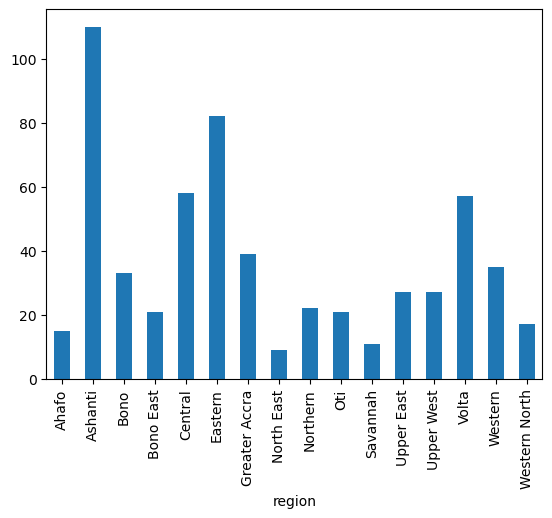

In [5]:
category_counts.plot(kind="bar")
plt.show()

# into residency 

residency
day             113
day/boarding    471
Name: count, dtype: int64
Residency: day
                                       school category         region gender  \
0  St. Thomas Aquinas Senior High, Cantoments        A  Greater Accra   boys   
1                      Derma Comm. Day School        B          Ahafo  mixed   
2        Al-Azariya Islamic Snr. High, Kumasi        B        Ashanti  mixed   
3     Nuru-Ameen Islamic Senior High, Asewase        B        Ashanti  mixed   
4             New Longoro Comm. School (Dega)        B      Bono East  mixed   

  residency agric business technical home_economics visual_arts general_arts  \
0       day   yes      yes        no             no         yes          yes   
1       day    no       no        no             no          no           no   
2       day    no      yes        no            yes          no          yes   
3       day    no      yes        no            yes         yes          yes   
4       day   yes      yes  

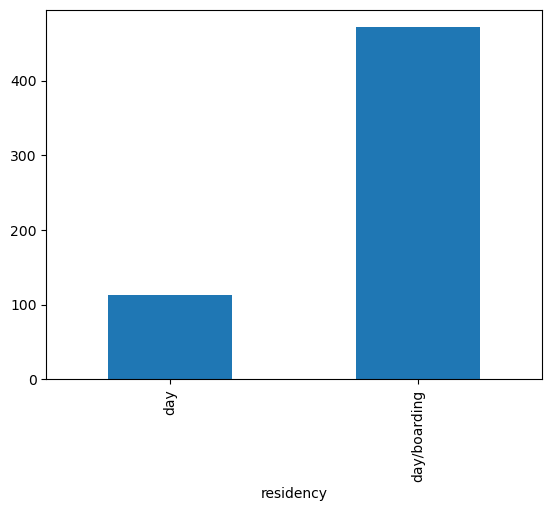

In [10]:
category_counts = df["residency"].value_counts().sort_index()
print(category_counts)

schools_by_residency = {
    residency: group.reset_index(drop=True)
    for residency, group in df.groupby("residency")
}
for residency, group in schools_by_residency.items():
    print(f"Residency: {residency}")
    print(group.head())
    print()

category_counts.plot(kind="bar")
plt.show()

In [11]:
import csv

FIELDS = list(df.columns)
CURRENT = file_path
OUT = "data/schools_notebook.csv"

clean_df = df.copy()

# Trim whitespace in text columns.
for column in clean_df.select_dtypes(include=["object", "string"]).columns:
    clean_df[column] = clean_df[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Normalize categorical values.
clean_df["category"] = clean_df["category"].str.upper()
for column in ["gender", "residency", "agric", "business", "technical",
               "home_economics", "visual_arts", "general_arts", "science"]:
    clean_df[column] = clean_df[column].str.lower()

# Remove rows without a school name and duplicate school names.
clean_df = clean_df.dropna(subset=["school"])
clean_df = clean_df[clean_df["school"] != ""]
clean_df = clean_df.drop_duplicates(
    subset=["school"], keep="first", ignore_index=True
)

# Convert missing values to empty strings for CSV output.
clean_df = clean_df.fillna("")
cleaned = clean_df.to_dict(orient="records")

print(f"Prepared {len(cleaned)} rows.")

Prepared 584 rows.


## 5. Compare with the current `data/schools.csv`

In [13]:
with open(CURRENT, newline="", encoding="utf-8") as f:
    current = {r["school"]: r for r in csv.DictReader(f)}
new = {c["school"]: c for c in cleaned} 

print("current:", len(current), "notebook:", len(new))
print("only in current:", sorted(set(current) - set(new))[:20])
print("only in notebook:", sorted(set(new) - set(current))[:20])
diffs = [(n, f, current[n][f], new[n][f]) for n in set(current) & set(new)
         for f in FIELDS[1:] if current[n][f] != new[n][f]]
print("field differences:", len(diffs))
diffs[:20]

current: 584 notebook: 584
only in current: []
only in notebook: []
field differences: 0


[]

## 6. Write the cleaned CSV

Written to `data/schools_notebook.csv` so the live `data/schools.csv` is not overwritten until the comparison above has been reviewed.

In [17]:
from pathlib import Path

OUT = Path("data/schools_notebook.csv")